In [1]:
import os
os.chdir('/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank')
print(os.getcwd())

/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank


In [3]:
import shutil
from pathlib import Path
import librosa
import numpy as np
import librosa.display
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import seaborn
seaborn.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams['axes.grid'] = False

import sys
sys.path.append("../../")
from modules.utils import metrics

sr = 16000
n_fft = 512
win_length=400
hop_length=100
save_dir = Path('exp/paper/SelfSE')

In [5]:
idx_list = ['p257_008', 'p257_033', 'p257_106', 'p232_250','p232_409']

wav_list = [("../exp/logs_self/ComplexSE_DCCRN/3a0/clean/{}.wav", "Clean"),
            ("../exp/logs_self/ComplexSE_DCCRN/3a0/noisy/{}.wav", "Noisy"),
            ("../exp/denoise/OMLSA/{}.wav", "OMLSA"),
            ("../exp/denoise/DCCRN/{}.wav", "DCCRN"),
            ("../exp/logs_self/N2N_ComplexSE_DCUNet/3a0/est/{}.wav", "Noise2Noise"),
            ("../exp/logs_self/N2N_UniSE_UNet/3a1/est/{}.wav", "NyTT"),
            ("../exp/logs_self/N2N_UniSE_UNet/3a6/est/{}.wav", "IDR"),
            ("../exp/logs_self/N2N_UniSE_UNet/3b15/est/{}.wav", "IterSE"),]
for file_idx in idx_list:
    for (wav, method) in wav_list:
        wav_path = Path(wav.format(file_idx))
        dest_dir = Path("samples_IterSE").joinpath(method)
        dest_dir.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(wav_path, dest_dir.joinpath(wav_path.name))

FileNotFoundError: [Errno 2] No such file or directory: '../exp/logs_self/ComplexSE_DCCRN/3a0/clean/p257_008.wav'

In [ ]:
_, model_list = zip(*wav_list)
html_str = "<tr><td>{}</td>"
for model in model_list:    
    print("<tr> <td>", model, "</td>")
    for file_idx in idx_list:
        wav_path = Path("samples").joinpath(model, "{}.wav".format(file_idx))
        print("""<td><audio controls=""><source src="{}"></audio></td>""".format(wav_path))
    print("</tr>")

Noisy  {PESQ: 1.48, eSTOI: 0.81, SI_SNR: 1.52}
OMLSA  {PESQ: 2.49, eSTOI: 0.83, SI_SNR: 16.78}
DCCRN  {PESQ: 2.76, eSTOI: 0.87, SI_SNR: 17.20}
Noise2Noise  {PESQ: 2.57, eSTOI: 0.84, SI_SNR: 17.01}
NyTT  {PESQ: 1.70, eSTOI: 0.82, SI_SNR: 7.63}
IDR-SE  {PESQ: 2.55, eSTOI: 0.85, SI_SNR: 16.62}
SelfSE  {PESQ: 2.68, eSTOI: 0.87, SI_SNR: 16.92}


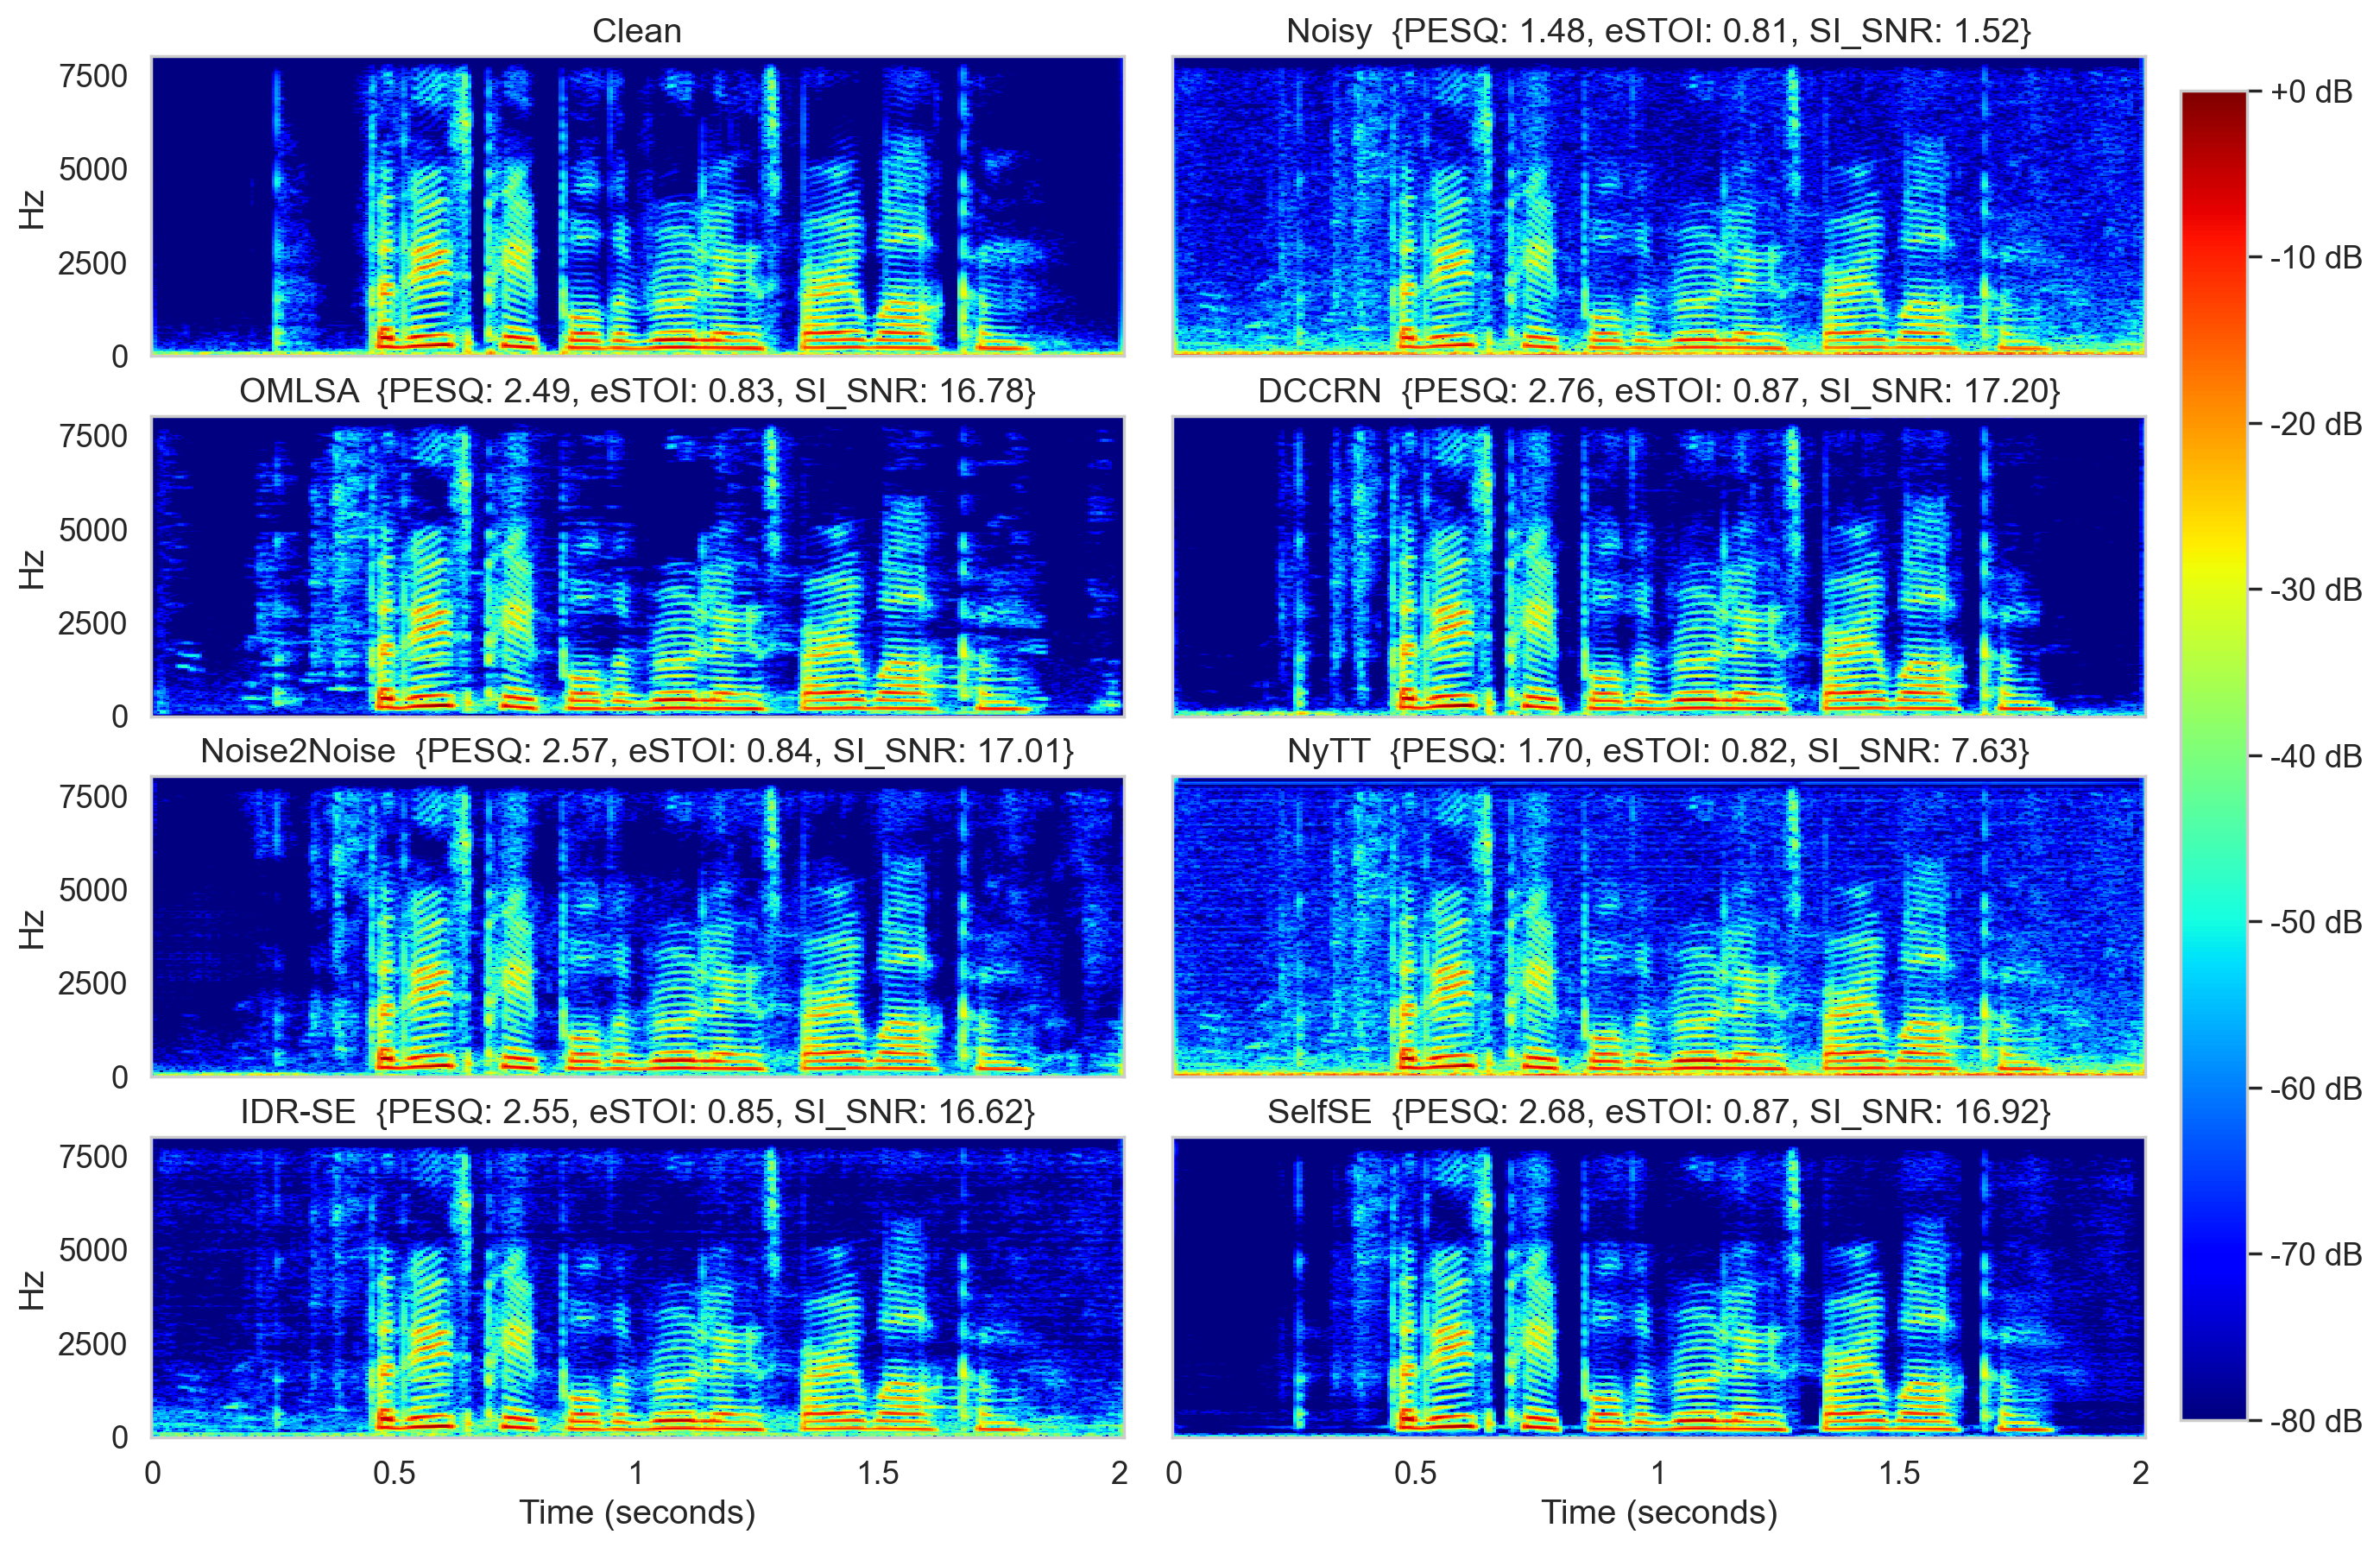

In [17]:
figsize = (15, 10)
nrows, ncols = 4, 2
file_idx = "p257_106"
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, figsize=figsize)
wav_list = [(f"exp/logs_self/ComplexSE_DCCRN/3a0/clean/{file_idx}.wav", "Clean"),
            (f"exp/logs_self/ComplexSE_DCCRN/3a0/noisy/{file_idx}.wav", "Noisy"),
            (f"exp/denoise/OMLSA/{file_idx}.wav", "OMLSA"),
            (f"exp/denoise/DCCRN/{file_idx}.wav", "DCCRN"),
            (f"exp/logs_self/N2N_ComplexSE_DCUNet/3a0/est/{file_idx}.wav", "Noise2Noise"),
            (f"exp/logs_self/N2N_UniSE_UNet/3a1/est/{file_idx}.wav", "NyTT"),
            (f"exp/logs/IterSE/3i2l10/est/{file_idx}.wav", r"IDR-SE"),
            (f"exp/logs/IterSE/3i9d1/est/{file_idx}.wav", r"SelfSE"),]
clean, _ = librosa.load(wav_list[0][0], sr=None)
for idx, (wav, method) in enumerate(wav_list):
    row_idx, col_idx = idx//ncols, idx%ncols
    y, sr = librosa.load(wav, sr=None)
    stft_y = librosa.stft(y, n_fft=n_fft)
    D = librosa.amplitude_to_db(np.abs(stft_y), ref=np.max)
    img = librosa.display.specshow(D, y_axis='linear', x_axis='s', sr=sr, hop_length=hop_length,
                                   ax=ax[row_idx, col_idx], cmap=('jet'))
    if idx == 0:
        title = method
    else:
        ref, est = clean, y
        est = est[:ref.shape[0]]
        ref = ref[:est.shape[0]]
        score = metrics.eval(ref, est, sr)
        title = "{:}  {{PESQ: {:.2f}, eSTOI: {:.2f}, SI_SNR: {:.2f}}}".format(method, score['PESQ'], 
                                                                              score['eSTOI'], score['SI_SNR'])
        print(title)
    ax[row_idx, col_idx].set(title=title)

for ax_i in ax:
    for ax_ij in ax_i:
        ax_ij.label_outer()
fig.colorbar(img, ax=ax, format="%+2.f dB")
fig.subplots_adjust(left=0,bottom=0.1,top=0.9,right=0.77,hspace=0.2,wspace=0.05)
plt.show()
fig.savefig(save_dir.joinpath(f"fig/{file_idx}.png"), dpi=120, bbox_inches='tight')